# Análisis Comparativo de Sesgos Demográficos en Modelos de Visión Supervisados y Auto-Supervisados

## Motivación

Este proyecto investiga si los modelos auto-supervisados (DINOv2, SimCLR) exhiben diferencias significativas en sesgos demográficos en comparación con modelos supervisados tradicionales (ResNet-50). Inspirado en el trabajo de Sirotkin et al. (2022), evaluamos los modelos en la tarea de clasificación facial del dataset FairFace utilizando métricas de sesgo (iEAT) y equidad (Demographic Parity, Equalized Odds).

## Objetivos

1. Evaluar el rendimiento general (Accuracy, F1-score) de modelos pre-entrenados en FairFace.
2. Cuantificar sesgos de asociación implícitos usando iEAT.
3. Medir equidad de grupos con Demographic Parity y Equalized Odds.
4. Analizar diferencias en sesgos entre modelos supervisados y auto-supervisados.

## Fundamentos Teóricos

**1. Modelos Supervisados vs Auto-Supervisados**

Supervisados (ResNet-50): requieren etiquetas humanas; aprenden correlaciones directas entre la imagen y la etiqueta.

Auto-supervisados (SimCLR, DINOv2): aprenden representaciones invariantes a transformaciones sin necesidad de etiquetas. Esto podría reducir ciertos sesgos, pero también puede amplificar patrones presentes en el propio dataset sin una señal que fuerce equilibrio.

**2. Sesgos Demográficos en Visión**

Los modelos de visión pueden presentar:

Sesgo de representación (datos desbalanceados).

Sesgo de asociación (agrupación de embeddings por atributos sensibles).

Sesgo de rendimiento (peor accuracy para ciertos grupos).

**3. Métricas Relevantes**

Demographic Parity (DP): compara la probabilidad de predicción positiva entre grupos.

Equalized Odds (EO): requiere que TPR y FPR sean similares entre grupos.

iEAT: mide separabilidad entre grupos en el espacio de embeddings mediante distancias coseno.

Accuracy / F1: rendimiento predictivo general.

## Metodología

**1. Modelos Analizados**

ResNet-50: modelo supervisado con etiquetas de ImageNet.

SimCLR (ResNet-50): modelo auto-supervisado contrastivo entrenado sobre ImageNet-1k (checkpoint `niels-c/resnet50_simclr_linhead`; solo se usa el backbone, no su cabeza lineal).

DINOv2: modelo auto-supervisado con preentrenamiento escalable y robusto.

Todos los modelos se evalúan sin fine-tuning, usando un clasificador lineal (regresión logística) entrenado sobre sus embeddings con un 70 % de los datos y evaluado en el 30 % restante (partición estratificada por raza y género).

**2. Dataset**

Se utiliza FairFace, un dataset balanceado por raza, género y edad.
Por restricciones de recursos se usa un subconjunto de 2500 imágenes, suficiente para comparar modelos pero no para conclusiones poblacionales.

**3. Métricas de Evaluación**

Rendimiento: Accuracy, F1-score.

Equidad: Demographic Parity y Equalized Odds.

Sesgo de Embeddings: iEAT.


## 1. Instalación de Dependencias

In [1]:
# Instalar dependencias necesarias
#!pip install -q torch torchvision transformers datasets scikit-learn pandas numpy matplotlib seaborn pillow scipy opencv-python-headless huggingface_hub safetensors -U

## 2. Importaciones y Configuración Inicial

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
from torchvision import models
import cv2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from scipy.spatial.distance import cosine
from scipy import stats

import warnings
warnings.filterwarnings('ignore')

# Configuración de dispositivo
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {device}')

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

Dispositivo: cpu


## 3. Carga del Dataset FairFace

In [3]:
# Cargar dataset FairFace desde HuggingFace
from datasets import load_dataset

print('Cargando dataset FairFace...')
# Usar el dataset de HuggingFace
dataset = load_dataset('HuggingFaceM4/FairFace', '0.25')
print(f'Dataset cargado. Split: {dataset.keys()}')

# Usar el conjunto de validación para la evaluación
fairface_data = dataset['validation']
print(f'Número de muestras: {len(fairface_data)}')
print(f'Columnas: {fairface_data.column_names}')

Cargando dataset FairFace...


README.md:   0%|          | 0.00/5.89k [00:00<?, ?B/s]

0.25/train-00000-of-00002-d405faba4f4b9b(…): reconstructing file:   0%|          |  0.00B /  250MB            

0.25/train-00000-of-00002-d405faba4f4b9b(…): downloading bytes:           |  0.00B            

0.25/train-00001-of-00002-dd3cb681647274(…): reconstructing file:   0%|          |  0.00B /  250MB            

0.25/train-00001-of-00002-dd3cb681647274(…): downloading bytes:           |  0.00B            

0.25/validation-00000-of-00001-951dbd63c(…): reconstructing file:   0%|          |  0.00B / 63.2MB            

0.25/validation-00000-of-00001-951dbd63c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/86744 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10954 [00:00<?, ? examples/s]

Dataset cargado. Split: dict_keys(['train', 'validation'])
Número de muestras: 10954
Columnas: ['image', 'age', 'gender', 'race', 'service_test']


In [4]:
# Esto es para cumplir con las limitaciones de recursos de Colab
sample_size = min(2500, len(fairface_data))
fairface_subset = fairface_data.select(range(sample_size))

print(f'Subconjunto de evaluación: {len(fairface_subset)} imágenes')

# Inspeccionar los datos
sample = fairface_subset[0]
print(f'\nEjemplo de muestra:')
for key in sample.keys():
    if key != 'image':
        print(f'  {key}: {sample[key]}')

Subconjunto de evaluación: 2500 imágenes

Ejemplo de muestra:
  age: 1
  gender: 0
  race: 0
  service_test: False


In [5]:
class FairFaceDataset(Dataset):
    def __init__(self, hf_dataset, transform=None, target_attribute='race'):
        self.hf_dataset = hf_dataset
        self.transform = transform
        self.target_attribute = target_attribute
        self.race_names = ['East Asian', 'Indian', 'Black', 'White',
                          'Middle Eastern', 'Latino_Hispanic', 'Southeast Asian']
        self.gender_names = ['Male', 'Female']
        self.age_names = ['0-2', '3-9', '10-19', '20-29', '30-39',
                         '40-49', '50-59', '60-69', 'more than 70']

    def __len__(self):
        return len(self.hf_dataset)

    def __getitem__(self, idx):
        sample = self.hf_dataset[idx]
        image = sample['image'].convert('RGB')

        if self.transform:
            image = self.transform(image)

        if self.target_attribute == 'race':
            label = sample['race']
            label_name = self.race_names[label]
        elif self.target_attribute == 'gender':
            label = sample['gender']
            label_name = self.gender_names[label]
        elif self.target_attribute == 'age':
            label = sample['age']
            label_name = self.age_names[label]
        else:
            raise ValueError(f"Atributo desconocido: {self.target_attribute}")

        # Obtener atributos demográficos adicionales para análisis de equidad
        demographics = {
            'race': self.race_names[sample['race']],
            'gender': self.gender_names[sample['gender']],
            'age': self.age_names[sample['age']]
        }

        return {
            'image': image,
            'label': label,
            'label_name': label_name,
            'demographics': demographics
        }

# Definir transformaciones de imagen
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

fairface_pytorch = FairFaceDataset(fairface_subset, transform=transform, target_attribute='gender')

# Crear DataLoader
batch_size = 32
fairface_loader = DataLoader(fairface_pytorch, batch_size=batch_size, shuffle=False, num_workers=0)

print(f'✓ DataLoader creado con batch_size={batch_size}')
print(f'✓ Número de batches: {len(fairface_loader)}')

# Verificar que funciona correctamente
print('\n--- Verificación ---')
test_batch = next(iter(fairface_loader))
print(f"Forma del batch de imágenes: {test_batch['image'].shape}")
print(f"Forma del batch de labels: {test_batch['label'].shape}")
print(f"Labels únicos en este batch: {torch.unique(test_batch['label']).tolist()}")
print(f"Ejemplo de label_name: {test_batch['label_name'][0]}")
print(f"Ejemplo de demographics: {test_batch['demographics']['race'][0]}, {test_batch['demographics']['gender'][0]}, {test_batch['demographics']['age'][0]}")

✓ DataLoader creado con batch_size=32
✓ Número de batches: 79

--- Verificación ---
Forma del batch de imágenes: torch.Size([32, 3, 224, 224])
Forma del batch de labels: torch.Size([32])
Labels únicos en este batch: [0, 1]
Ejemplo de label_name: Male
Ejemplo de demographics: East Asian, Male, 3-9


## 4. Carga de Modelos Pre-entrenados

In [6]:
# 4.1. Cargar ResNet-50 (Modelo Supervisado)
print('Cargando ResNet-50 pre-entrenado...')
resnet50 = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
resnet50 = resnet50.to(device)
resnet50.eval()
print('ResNet-50 cargado exitosamente')

Cargando ResNet-50 pre-entrenado...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 88.4MB/s]


ResNet-50 cargado exitosamente


In [7]:
# 4.2. Cargar DINOv2 (Modelo Auto-Supervisado)
print('Cargando DINOv2 pre-entrenado...')
try:
    from transformers import AutoModel, AutoImageProcessor

    dinov2_processor = AutoImageProcessor.from_pretrained('facebook/dinov2-small')
    dinov2_model = AutoModel.from_pretrained('facebook/dinov2-small')
    dinov2_model = dinov2_model.to(device)
    dinov2_model.eval()
    print('DINOv2 cargado exitosamente')
except Exception as e:
    print(f'Error al cargar DINOv2: {e}')
    print('Se continuará sin DINOv2')
    dinov2_model = None

Cargando DINOv2 pre-entrenado...


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

DINOv2 cargado exitosamente


In [8]:
# 4.3. Cargar SimCLR (Modelo Auto-Supervisado, ResNet-50 entrenado con pérdida contrastiva en ImageNet-1k)
# Checkpoint: backbone SimCLR (AndrewAtanov/simclr-pytorch) empaquetado en formato torchvision.
# Su cabeza lineal (fc) NO se usa: los embeddings se extraen antes de ella.
print('Cargando SimCLR pre-entrenado...')
try:
    from huggingface_hub import hf_hub_download
    from safetensors.torch import load_file

    simclr_model = models.resnet50(weights=None)
    state = load_file(hf_hub_download('niels-c/resnet50_simclr_linhead', 'resnet50_simclr_linhead.safetensors'))
    simclr_model.load_state_dict(state)
    simclr_model = simclr_model.to(device).eval()

    # Comprobación: no deben ser los mismos pesos que el ResNet-50 supervisado
    same = torch.allclose(simclr_model.conv1.weight.cpu(), resnet50.conv1.weight.cpu())
    assert not same, 'SimCLR tiene los mismos pesos que ResNet-50 supervisado'
    print('SimCLR (ResNet-50 contrastivo) cargado exitosamente')
except Exception as e:
    print(f'Error al cargar SimCLR: {e}')
    simclr_model = None


Cargando SimCLR pre-entrenado...


resnet50_simclr_linhead.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

resnet50_simclr_linhead.safetensors: downloading bytes:           |  0.00B            

SimCLR (ResNet-50 contrastivo) cargado exitosamente


## 5. Funciones Auxiliares para Extracción de Embeddings

In [9]:
# Extraer embeddings de ResNet (sin capa fc)
def extract_embeddings_resnet(model, dataloader, device):
    model_no_fc = nn.Sequential(*list(model.children())[:-1])
    model_no_fc = model_no_fc.to(device)
    model_no_fc.eval()

    embeddings, labels, demographics_race = [], [], []

    with torch.no_grad():
        for batch in dataloader:
            images = batch['image'].to(device)
            batch_labels = batch['label'].cpu().numpy()
            features = model_no_fc(images)
            features = features.view(features.size(0), -1)

            embeddings.append(features.cpu().numpy())
            labels.extend(batch_labels)

            demographics_race.extend(batch['demographics']['race'])

    embeddings = np.vstack(embeddings)
    return embeddings, np.array(labels), demographics_race


def extract_embeddings_dinov2(model, processor, dataloader, device):
    """Extrae embeddings de DINOv2"""
    embeddings = []
    labels = []
    demographics_race = []

    with torch.no_grad():
        for batch in dataloader:
            # Procesar imágenes con el procesador de DINOv2
            # Desnormalizar (mean/std de ImageNet) antes de convertir a PIL; si no, la imagen queda corrupta
            mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
            std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
            imgs = (batch['image'].cpu() * std + mean).clamp(0, 1)
            images_pil = [transforms.ToPILImage()(img) for img in imgs]
            inputs = processor(images=images_pil, return_tensors='pt').to(device)

            # Obtener embeddings
            outputs = model(**inputs)
            features = outputs.last_hidden_state[:, 0, :]

            embeddings.append(features.cpu().numpy())
            labels.extend(batch['label'].numpy())
            demographics_race.extend(batch['demographics']['race'])

    embeddings = np.vstack(embeddings)
    return embeddings, np.array(labels), demographics_race

## 6. Extracción de Embeddings

In [10]:
# Extraer embeddings de ResNet-50
print('Extrayendo embeddings de ResNet-50...')
resnet_embeddings, resnet_labels, resnet_race = extract_embeddings_resnet(
    resnet50, fairface_loader, device
)
print(f'ResNet-50 embeddings shape: {resnet_embeddings.shape}')
print(f'ResNet-50 labels shape: {resnet_labels.shape}')

Extrayendo embeddings de ResNet-50...
ResNet-50 embeddings shape: (2500, 2048)
ResNet-50 labels shape: (2500,)


In [11]:
# Extraer embeddings de DINOv2 (si está disponible)
if dinov2_model is not None:
    print('Extrayendo embeddings de DINOv2...')
    dinov2_embeddings, dinov2_labels, dinov2_race = extract_embeddings_dinov2(
        dinov2_model, dinov2_processor, fairface_loader, device
    )
    print(f'DINOv2 embeddings shape: {dinov2_embeddings.shape}')
else:
    print('DINOv2 no disponible, continuando con ResNet-50 y SimCLR')

Extrayendo embeddings de DINOv2...
DINOv2 embeddings shape: (2500, 384)


In [12]:
# Extraer embeddings de SimCLR (ResNet-50 contrastivo)
print('Extrayendo embeddings de SimCLR...')
simclr_embeddings, simclr_labels, simclr_race = extract_embeddings_resnet(
    simclr_model, fairface_loader, device
)
print(f'SimCLR embeddings shape: {simclr_embeddings.shape}')

Extrayendo embeddings de SimCLR...
SimCLR embeddings shape: (2500, 2048)


## 7. Normalización de Embeddings

In [13]:
# Función para aplanar embeddings si tienen más de 2 dimensiones
def flatten_embeddings(embeddings):
    """Aplana embeddings de cualquier dimensión a 2D (n_samples, n_features)"""
    if embeddings.ndim > 2:
        print(f'  Aplanando desde {embeddings.shape} a', end=' ')
        # Aplanar todas las dimensiones excepto la primera (batch)
        embeddings = embeddings.reshape(embeddings.shape[0], -1)
        print(f'{embeddings.shape}')
    return embeddings

# Aplanar embeddings si es necesario
print('\nAplanando embeddings si es necesario...')
resnet_embeddings = flatten_embeddings(resnet_embeddings)
if dinov2_model is not None:
    dinov2_embeddings = flatten_embeddings(dinov2_embeddings)
simclr_embeddings = flatten_embeddings(simclr_embeddings)

print('\n Embeddings procesados:')
print(f'  ResNet: {resnet_embeddings.shape}')
if dinov2_model is not None:
    print(f'  DINOv2: {dinov2_embeddings.shape}')
print(f'  SimCLR: {simclr_embeddings.shape}')

# Normalizar embeddings para cálculos de distancia coseno
def normalize_embeddings(embeddings):
    """Normaliza embeddings a norma L2"""
    norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
    return embeddings / (norms + 1e-8)

resnet_embeddings_norm = normalize_embeddings(resnet_embeddings)
if dinov2_model is not None:
    dinov2_embeddings_norm = normalize_embeddings(dinov2_embeddings)
simclr_embeddings_norm = normalize_embeddings(simclr_embeddings)

print('Embeddings normalizados')


Aplanando embeddings si es necesario...

 Embeddings procesados:
  ResNet: (2500, 2048)
  DINOv2: (2500, 384)
  SimCLR: (2500, 2048)
Embeddings normalizados


## 8. Análisis de Rendimiento (Accuracy, F1-score)

In [14]:
# Partición train/test estratificada por raza y género (las métricas se calculan SOLO sobre test)
strata = [f'{r}_{g}' for r, g in zip(resnet_race, resnet_labels)]
idx_train, idx_test = train_test_split(
    np.arange(len(resnet_labels)), test_size=0.3, stratify=strata, random_state=42
)
y_train, y_test = resnet_labels[idx_train], resnet_labels[idx_test]
race_test = [resnet_race[i] for i in idx_test]
print(f'Train: {len(idx_train)} | Test: {len(idx_test)}')

print('Entrenando clasificadores lineales...')

# ResNet-50
clf_resnet = LogisticRegression(max_iter=1000, random_state=42)
clf_resnet.fit(resnet_embeddings_norm[idx_train], y_train)
resnet_predictions = clf_resnet.predict(resnet_embeddings_norm[idx_test])

# DINOv2
if dinov2_model is not None:
    clf_dinov2 = LogisticRegression(max_iter=1000, random_state=42)
    clf_dinov2.fit(dinov2_embeddings_norm[idx_train], y_train)
    dinov2_predictions = clf_dinov2.predict(dinov2_embeddings_norm[idx_test])

# SimCLR
clf_simclr = LogisticRegression(max_iter=1000, random_state=42)
clf_simclr.fit(simclr_embeddings_norm[idx_train], y_train)
simclr_predictions = clf_simclr.predict(simclr_embeddings_norm[idx_test])

print('Clasificadores entrenados')


Train: 1750 | Test: 750
Entrenando clasificadores lineales...
Clasificadores entrenados



Métricas de rendimiento:
           Accuracy  F1-score
ResNet-50  0.776000  0.774327
DINOv2     0.873333  0.873452
SimCLR     0.606667  0.569269


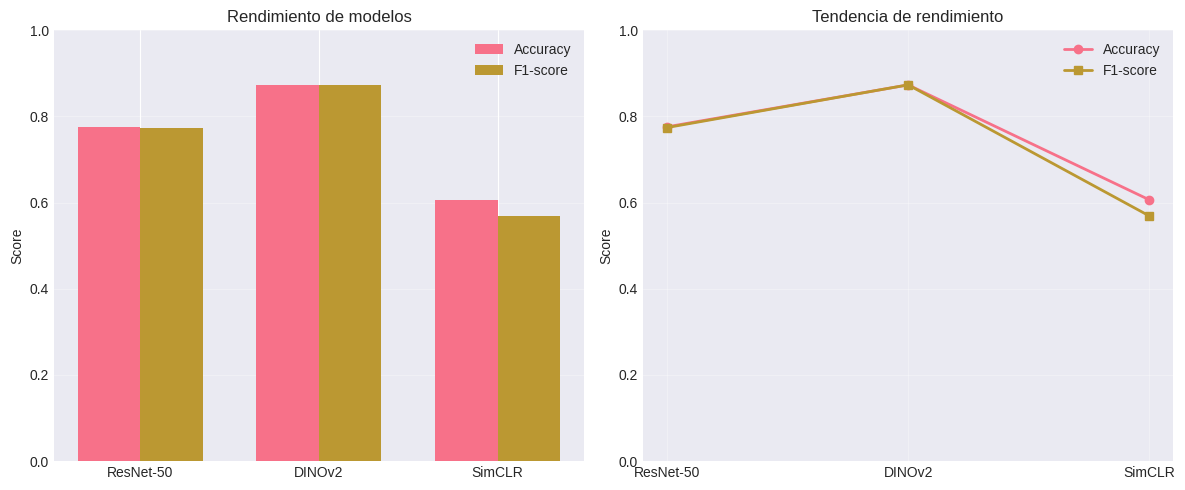

In [15]:
performance_results = {}

# ResNet-50
resnet_acc = accuracy_score(y_test, resnet_predictions)
resnet_f1 = f1_score(y_test, resnet_predictions, average='weighted', zero_division=0)
performance_results['ResNet-50'] = {'Accuracy': resnet_acc, 'F1-score': resnet_f1}

# DINOv2
if dinov2_model is not None:
    dinov2_acc = accuracy_score(y_test, dinov2_predictions)
    dinov2_f1 = f1_score(y_test, dinov2_predictions, average='weighted', zero_division=0)
    performance_results['DINOv2'] = {'Accuracy': dinov2_acc, 'F1-score': dinov2_f1}

# SimCLR
simclr_acc = accuracy_score(y_test, simclr_predictions)
simclr_f1 = f1_score(y_test, simclr_predictions, average='weighted', zero_division=0)
performance_results['SimCLR'] = {'Accuracy': simclr_acc, 'F1-score': simclr_f1}

# Mostrar resultados
perf_df = pd.DataFrame(performance_results).T
print('\nMétricas de rendimiento:')
print(perf_df)

# Visualizar
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = list(performance_results.keys())
accuracies = [performance_results[m]['Accuracy'] for m in models]
f1_scores = [performance_results[m]['F1-score'] for m in models]

x = np.arange(len(models))
width = 0.35

axes[0].bar(x - width/2, accuracies, width, label='Accuracy')
axes[0].bar(x + width/2, f1_scores, width, label='F1-score')
axes[0].set_ylabel('Score')
axes[0].set_title('Rendimiento de modelos')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, 1])

# Gráfico de comparación
axes[1].plot(models, accuracies, marker='o', label='Accuracy', linewidth=2)
axes[1].plot(models, f1_scores, marker='s', label='F1-score', linewidth=2)
axes[1].set_ylabel('Score')
axes[1].set_title('Tendencia de rendimiento')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

## 9. Análisis de Equidad - Demographic Parity y Equalized Odds

In [16]:
def calculate_fairness_metrics(predictions, labels, demographics_race, model_name):
    """
    Calcula métricas de equidad por grupo racial para una tarea de clasificación.
    predictions: predicciones del modelo (ej: género)
    labels: etiquetas verdaderas (ej: género)
    demographics_race: lista de strings con la raza de cada muestra
    """
    print(f"[{model_name}] len(predictions)={len(predictions)}, len(labels)={len(labels)}, len(demographics_race)={len(demographics_race)}")

    min_len = min(len(predictions), len(labels), len(demographics_race))
    predictions = predictions[:min_len]
    labels = labels[:min_len]
    demographics_race = demographics_race[:min_len]

    df = pd.DataFrame({
        'prediction': predictions,
        'label': labels,
        'race': demographics_race
    })

    dp_results, eo_results, accuracy_results = {}, {}, {}

    # Determinar clase positiva (la más frecuente)
    positive_class = stats.mode(df['label'], keepdims=False)[0]
    print(f"[{model_name}] Clase positiva: {positive_class}")

    for race in df['race'].unique():
        group = df[df['race'] == race]

        # DEMOGRAPHIC PARITY
        dp = (group['prediction'] == positive_class).mean()
        dp_results[race] = dp

        # ACCURACY por grupo
        accuracy = (group['prediction'] == group['label']).mean()
        accuracy_results[race] = accuracy

        # EQUALIZED ODDS: TPR y FPR
        positive_cases = group[group['label'] == positive_class]
        negative_cases = group[group['label'] != positive_class]

        if len(positive_cases) > 0:
            tpr = (positive_cases['prediction'] == positive_class).mean()
        else:
            tpr = 0.0

        if len(negative_cases) > 0:
            fpr = (negative_cases['prediction'] == positive_class).mean()
        else:
            fpr = 0.0

        eo_results[race] = {'TPR': tpr, 'FPR': fpr}

    return dp_results, eo_results, accuracy_results


# Calcular para cada modelo
resnet_dp, resnet_eo, resnet_acc = calculate_fairness_metrics(
    resnet_predictions, y_test, race_test, 'ResNet-50'
)

if dinov2_model is not None:
    dinov2_dp, dinov2_eo, dinov2_acc = calculate_fairness_metrics(
        dinov2_predictions, y_test, race_test, 'DINOv2'
    )

simclr_dp, simclr_eo, simclr_acc = calculate_fairness_metrics(
    simclr_predictions, y_test, race_test, 'SimCLR'
)

print('\n✓ Métricas de equidad calculadas')

[ResNet-50] len(predictions)=750, len(labels)=750, len(demographics_race)=750
[ResNet-50] Clase positiva: 0
[DINOv2] len(predictions)=750, len(labels)=750, len(demographics_race)=750
[DINOv2] Clase positiva: 0
[SimCLR] len(predictions)=750, len(labels)=750, len(demographics_race)=750
[SimCLR] Clase positiva: 0

✓ Métricas de equidad calculadas


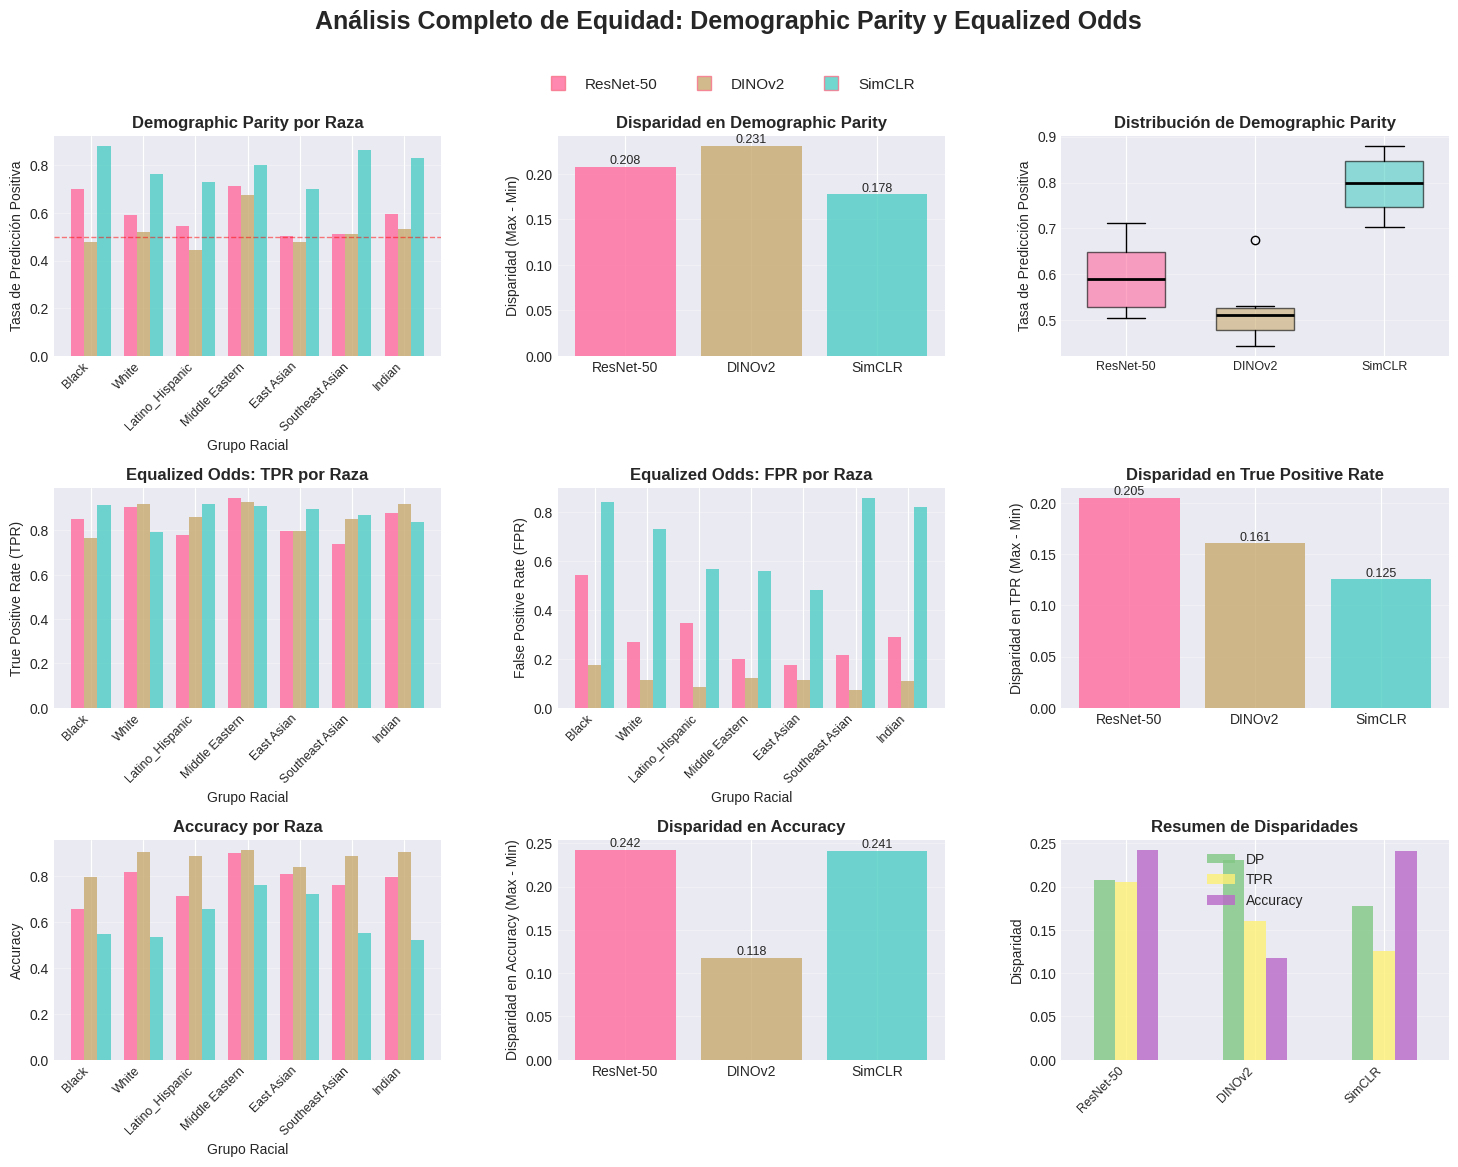


RESUMEN DE MÉTRICAS DE EQUIDAD

ResNet-50:
  Disparidad en Demographic Parity: 0.2080
  Disparidad en TPR: 0.2047
  Disparidad en Accuracy: 0.2419

DINOv2:
  Disparidad en Demographic Parity: 0.2306
  Disparidad en TPR: 0.1606
  Disparidad en Accuracy: 0.1176

SimCLR:
  Disparidad en Demographic Parity: 0.1776
  Disparidad en TPR: 0.1255
  Disparidad en Accuracy: 0.2412


In [17]:
# Métricas calculadas sobre el conjunto de TEST
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 3, hspace=0.6, wspace=0.3)

models_dp = {'ResNet-50': resnet_dp}
models_eo = {'ResNet-50': resnet_eo}
models_acc = {'ResNet-50': resnet_acc}

if dinov2_model is not None:
    models_dp['DINOv2'] = dinov2_dp
    models_eo['DINOv2'] = dinov2_eo
    models_acc['DINOv2'] = dinov2_acc

models_dp['SimCLR'] = simclr_dp
models_eo['SimCLR'] = simclr_eo
models_acc['SimCLR'] = simclr_acc

races = list(resnet_dp.keys())
x = np.arange(len(races))
width = 0.25
colors = ['#FF6B9D', '#C8A96F', '#4ECDC4']

ax1 = fig.add_subplot(gs[0, 0])
for i, (model_name, dp_dict) in enumerate(models_dp.items()):
    values = [dp_dict[race] for race in races]
    ax1.bar(x + i*width, values, width, color=colors[i], alpha=0.8)

ax1.set_xlabel('Grupo Racial', fontsize=10)
ax1.set_ylabel('Tasa de Predicción Positiva', fontsize=10)
ax1.set_title('Demographic Parity por Raza', fontsize=12, fontweight='bold')
ax1.set_xticks(x + width)
ax1.set_xticklabels(races, rotation=45, ha='right', fontsize=9)
ax1.grid(axis='y', alpha=0.3)
ax1.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, linewidth=1)

ax2 = fig.add_subplot(gs[0, 1])
dp_disparities = {}
for model_name, dp_dict in models_dp.items():
    values = list(dp_dict.values())
    dp_disparities[model_name] = max(values) - min(values)

bars = ax2.bar(dp_disparities.keys(), dp_disparities.values(),
               color=colors[:len(dp_disparities)], alpha=0.8)
ax2.set_ylabel('Disparidad (Max - Min)', fontsize=10)
ax2.set_title('Disparidad en Demographic Parity', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.3f}', ha='center', va='bottom', fontsize=9)

ax3 = fig.add_subplot(gs[0, 2])
for i, (model_name, dp_dict) in enumerate(models_dp.items()):
    values = list(dp_dict.values())
    ax3.boxplot([values], positions=[i], widths=0.6,
                patch_artist=True,
                boxprops=dict(facecolor=colors[i], alpha=0.6),
                medianprops=dict(color='black', linewidth=2))

ax3.set_xticks(range(len(models_dp)))
ax3.set_xticklabels(models_dp.keys(), fontsize=9)
ax3.set_ylabel('Tasa de Predicción Positiva', fontsize=10)
ax3.set_title('Distribución de Demographic Parity', fontsize=12, fontweight='bold')
ax3.grid(axis='y', alpha=0.3)


ax4 = fig.add_subplot(gs[1, 0])
for i, (model_name, eo_dict) in enumerate(models_eo.items()):
    tpr_values = [eo_dict[race]['TPR'] for race in races]
    ax4.bar(x + i*width, tpr_values, width, color=colors[i], alpha=0.8)

ax4.set_xlabel('Grupo Racial', fontsize=10)
ax4.set_ylabel('True Positive Rate (TPR)', fontsize=10)
ax4.set_title('Equalized Odds: TPR por Raza', fontsize=12, fontweight='bold')
ax4.set_xticks(x + width)
ax4.set_xticklabels(races, rotation=45, ha='right', fontsize=9)
ax4.grid(axis='y', alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
for i, (model_name, eo_dict) in enumerate(models_eo.items()):
    fpr_values = [eo_dict[race]['FPR'] for race in races]
    ax5.bar(x + i*width, fpr_values, width, color=colors[i], alpha=0.8)

ax5.set_xlabel('Grupo Racial', fontsize=10)
ax5.set_ylabel('False Positive Rate (FPR)', fontsize=10)
ax5.set_title('Equalized Odds: FPR por Raza', fontsize=12, fontweight='bold')
ax5.set_xticks(x + width)
ax5.set_xticklabels(races, rotation=45, ha='right', fontsize=9)
ax5.grid(axis='y', alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
tpr_disparities = {}
for model_name, eo_dict in models_eo.items():
    tpr_values = [eo_dict[race]['TPR'] for race in races]
    tpr_disparities[model_name] = max(tpr_values) - min(tpr_values)

bars = ax6.bar(tpr_disparities.keys(), tpr_disparities.values(),
               color=colors[:len(tpr_disparities)], alpha=0.8)
ax6.set_ylabel('Disparidad en TPR (Max - Min)', fontsize=10)
ax6.set_title('Disparidad en True Positive Rate', fontsize=12, fontweight='bold')
ax6.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.3f}', ha='center', va='bottom', fontsize=9)

ax7 = fig.add_subplot(gs[2, 0])
for i, (model_name, acc_dict) in enumerate(models_acc.items()):
    values = [acc_dict[race] for race in races]
    ax7.bar(x + i*width, values, width, color=colors[i], alpha=0.8)

ax7.set_xlabel('Grupo Racial', fontsize=10)
ax7.set_ylabel('Accuracy', fontsize=10)
ax7.set_title('Accuracy por Raza', fontsize=12, fontweight='bold')
ax7.set_xticks(x + width)
ax7.set_xticklabels(races, rotation=45, ha='right', fontsize=9)
ax7.grid(axis='y', alpha=0.3)

ax8 = fig.add_subplot(gs[2, 1])
acc_disparities = {}
for model_name, acc_dict in models_acc.items():
    values = list(acc_dict.values())
    acc_disparities[model_name] = max(values) - min(values)

bars = ax8.bar(acc_disparities.keys(), acc_disparities.values(),
               color=colors[:len(acc_disparities)], alpha=0.8)
ax8.set_ylabel('Disparidad en Accuracy (Max - Min)', fontsize=10)
ax8.set_title('Disparidad en Accuracy', fontsize=12, fontweight='bold')
ax8.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax8.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.3f}', ha='center', va='bottom', fontsize=9)

ax9 = fig.add_subplot(gs[2, 2])
disparities_summary = pd.DataFrame({
    'DP': list(dp_disparities.values()),
    'TPR': list(tpr_disparities.values()),
    'Accuracy': list(acc_disparities.values())
}, index=list(dp_disparities.keys()))

disparities_summary.plot(kind='bar', ax=ax9,
                         color=['#81C784', '#FFF176', '#BA68C8'], alpha=0.8)
ax9.set_ylabel('Disparidad', fontsize=10)
ax9.set_title('Resumen de Disparidades', fontsize=12, fontweight='bold')
ax9.set_xticklabels(ax9.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax9.grid(axis='y', alpha=0.3)

# Leyenda global
handles = []
labels = []

for i, model_name in enumerate(models_dp.keys()):
    handles.append(
        plt.Line2D([0], [0], marker='s', linestyle='',
                   markersize=10, markerfacecolor=colors[i], alpha=0.8)
    )
    labels.append(model_name)

fig.legend(handles, labels, loc='upper center',
           ncol=len(labels), fontsize=11,
           frameon=False, bbox_to_anchor=(0.5, 0.94))

plt.suptitle(
    'Análisis Completo de Equidad: Demographic Parity y Equalized Odds',
    fontsize=18,
    fontweight='bold',
    y=0.985
)


plt.show()

# Resumen numerico
print('\n' + '='*60)
print('RESUMEN DE MÉTRICAS DE EQUIDAD')
print('='*60)

for model_name in models_dp.keys():
    print(f'\n{model_name}:')
    print(f'  Disparidad en Demographic Parity: {dp_disparities[model_name]:.4f}')
    print(f'  Disparidad en TPR: {tpr_disparities[model_name]:.4f}')
    print(f'  Disparidad en Accuracy: {acc_disparities[model_name]:.4f}')


## 10. Análisis de Sesgo -  simplifcación de iEAT (Image Embedding Association Test)

### ¿Qué mide esta métrica?

Calculamos la **distancia coseno media entre los centroides de cada grupo racial** en el espacio de embeddings. Un valor alto indica que las razas quedan más separadas en esa representación.

### Limitaciones importantes

- **No es el iEAT original** (Steed & Caliskan, 2021), que compara conjuntos de imágenes objetivo con conjuntos de atributos y devuelve un tamaño de efecto. Aquí solo medimos *separabilidad* entre grupos, no asociaciones con conceptos como "agradable/desagradable".
- La separación racial en embeddings no implica por sí sola que el modelo use la raza para predecir el género.
- Los valores **no son estrictamente comparables entre modelos** con distinta dimensionalidad (ResNet/SimCLR: 2048; DINOv2: 384).
- Los umbrales 0.3 y 0.5 usados en las gráficas son **heurísticos**, sin base estadística.
- Se calcula sobre las 2 500 imágenes (no usa clasificador, por lo que no hay fuga train/test).
- **Geometría del embedding:** la distancia coseno entre centroides depende de cómo está distribuido el espacio de cada modelo. Si las características comparten un componente común grande (p. ej., activaciones no negativas tras ReLU), todos los centroides quedan casi alineados y la distancia sale pequeña **sin que eso signifique menos sesgo**. Los resultados de la sección 13 muestran justo este problema, por lo que esta métrica no debe usarse para ordenar modelos.


In [18]:
def calculate_ieat_simple(embeddings, labels, demographics_race, model_name):
    """
    Calcula un índice de sesgo simple basado en distancias coseno
    entre grupos demográficos (p. ej. razas) en el espacio de embeddings.
    """
    min_len = min(len(embeddings), len(labels), len(demographics_race))
    embeddings = embeddings[:min_len]
    labels = labels[:min_len]
    demographics_race = demographics_race[:min_len]

    norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
    embeddings_norm = embeddings / (norms + 1e-8) # Normalizar para similitud coseno

    # Centroide por grupo racial
    races = list(set(demographics_race))
    race_embeddings = {}

    for race in races:
        race_mask = np.array([d == race for d in demographics_race])
        if race_mask.sum() > 0:
            race_embeddings[race] = embeddings_norm[race_mask].mean(axis=0)

    # Calcular distancias entre grupos
    bias_scores = {}
    races_list = list(race_embeddings.keys())

    for i, race1 in enumerate(races_list):
        for race2 in races_list[i+1:]:
            emb1 = race_embeddings[race1]
            emb2 = race_embeddings[race2]
            dist = 1 - np.dot(emb1, emb2)
            bias_scores[f'{race1} vs {race2}'] = dist

    avg_bias = np.mean(list(bias_scores.values()))

    print(f"[{model_name}] iEAT calculado con {min_len} muestras ({len(races)} grupos)")

    return {
        'model': model_name,
        'avg_bias': avg_bias,
        'pairwise_biases': bias_scores
    }

# Calcular iEAT para cada modelo
resnet_ieat = calculate_ieat_simple(resnet_embeddings, resnet_labels, resnet_race, 'ResNet-50')
if dinov2_model is not None:
    dinov2_ieat = calculate_ieat_simple(dinov2_embeddings, dinov2_labels, dinov2_race, 'DINOv2')
simclr_ieat = calculate_ieat_simple(simclr_embeddings, simclr_labels, simclr_race, 'SimCLR')

print('\niEAT Results (Average Bias Score):')
print(f'ResNet-50: {resnet_ieat["avg_bias"]:.4f}')
if dinov2_model is not None:
    print(f'DINOv2: {dinov2_ieat["avg_bias"]:.4f}')
print(f'SimCLR: {simclr_ieat["avg_bias"]:.4f}')

[ResNet-50] iEAT calculado con 2500 muestras (7 grupos)
[DINOv2] iEAT calculado con 2500 muestras (7 grupos)
[SimCLR] iEAT calculado con 2500 muestras (7 grupos)

iEAT Results (Average Bias Score):
ResNet-50: 0.4527
DINOv2: 0.6624
SimCLR: 0.0472


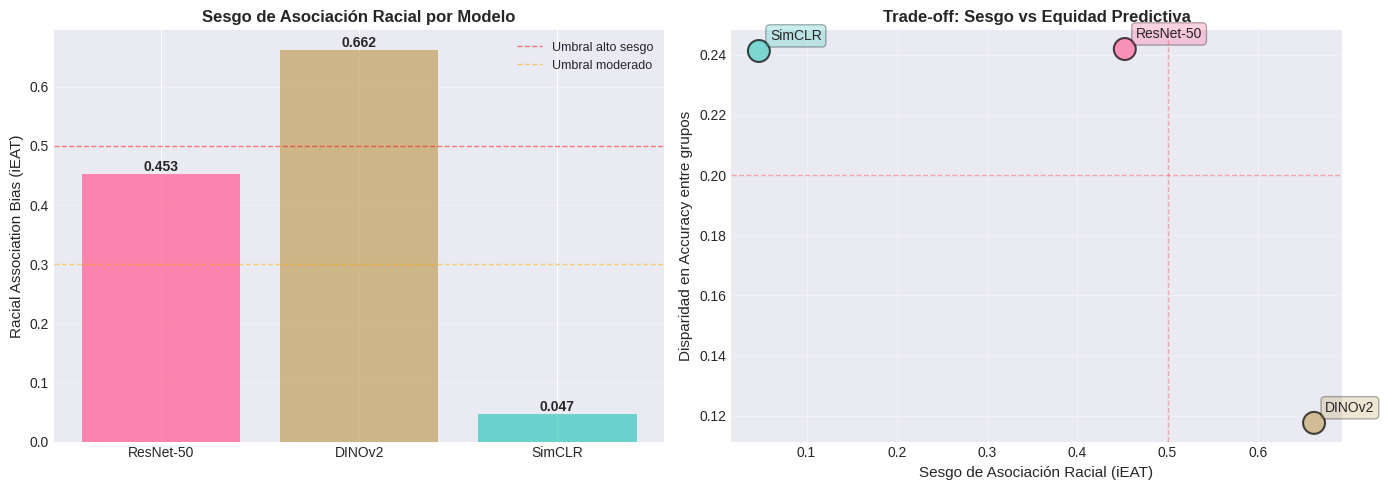


ANÁLISIS DE SESGO Y EQUIDAD

ResNet-50:
  iEAT (Sesgo de Asociación):     0.4527 (MODERADO)
  Disparidad en Accuracy:        0.2419 (ALTA)
  MIXTO: Trade-off entre sesgo y equidad

DINOv2:
  iEAT (Sesgo de Asociación):     0.6624 (ALTO)
  Disparidad en Accuracy:        0.1176 (MODERADA)
  MIXTO: Trade-off entre sesgo y equidad

SimCLR:
  iEAT (Sesgo de Asociación):     0.0472 (BAJO)
  Disparidad en Accuracy:        0.2412 (ALTA)
  MIXTO: Trade-off entre sesgo y equidad

INTERPRETACIÓN:
- Eje X (iEAT): Cuánto el modelo separa razas en su espacio interno
- Eje Y (Accuracy): Cuánto varía el rendimiento entre grupos raciales
- Ideal: Esquina inferior izquierda (bajo sesgo, baja disparidad)


In [19]:
# Visualizar resultados
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ieat_models = ['ResNet-50']
ieat_values = [resnet_ieat['avg_bias']]
if dinov2_model is not None:
    ieat_models.append('DINOv2')
    ieat_values.append(dinov2_ieat['avg_bias'])
ieat_models.append('SimCLR')
ieat_values.append(simclr_ieat['avg_bias'])

colors = ['#FF6B9D' if 'ResNet' in m else ('#C8A96F' if 'DINOv2' in m else '#4ECDC4') for m in ieat_models]

# Gráfico 1: iEAT por modelo
bars = axes[0].bar(ieat_models, ieat_values, color=colors, alpha=0.8)
axes[0].set_ylabel('Racial Association Bias (iEAT)', fontsize=11)
axes[0].set_title('Sesgo de Asociación Racial por Modelo', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, linewidth=1, label='Umbral alto sesgo')
axes[0].axhline(y=0.3, color='orange', linestyle='--', alpha=0.5, linewidth=1, label='Umbral moderado')
axes[0].legend(fontsize=9)

# Añadir valores sobre las barras
for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Gráfico 2: Trade-off entre iEAT y Equidad
equidad_disparities = [acc_disparities[model] for model in ieat_models]

axes[1].scatter(ieat_values, equidad_disparities, s=250, c=colors, alpha=0.7, edgecolors='black', linewidth=1.5)
for i, model in enumerate(ieat_models):
    axes[1].annotate(model, (ieat_values[i], equidad_disparities[i]),
                    xytext=(8, 8), textcoords='offset points', fontsize=10,
                    bbox=dict(boxstyle='round,pad=0.3', facecolor=colors[i], alpha=0.3))

axes[1].set_xlabel('Sesgo de Asociación Racial (iEAT)', fontsize=11)
axes[1].set_ylabel('Disparidad en Accuracy entre grupos', fontsize=11)
axes[1].set_title('Trade-off: Sesgo vs Equidad Predictiva', fontsize=12, fontweight='bold')
axes[1].grid(alpha=0.3)

# Añadir líneas de referencia
axes[1].axvline(x=0.5, color='red', linestyle='--', alpha=0.3, linewidth=1)
axes[1].axhline(y=0.2, color='red', linestyle='--', alpha=0.3, linewidth=1)

plt.tight_layout()
plt.show()

# Resumen interpretativo
print('\n' + '='*70)
print('ANÁLISIS DE SESGO Y EQUIDAD')
print('='*70)
for i, model in enumerate(ieat_models):
    rab_level = 'ALTO' if ieat_values[i] > 0.5 else ('MODERADO' if ieat_values[i] > 0.3 else 'BAJO')
    eq_level = 'ALTA' if equidad_disparities[i] > 0.2 else ('MODERADA' if equidad_disparities[i] > 0.1 else 'BAJA')

    print(f'\n{model}:')
    print(f'  iEAT (Sesgo de Asociación):     {ieat_values[i]:.4f} ({rab_level})')
    print(f'  Disparidad en Accuracy:        {equidad_disparities[i]:.4f} ({eq_level})')

    if ieat_values[i] > 0.5 and equidad_disparities[i] > 0.2:
        print(f'  CRÍTICO: Alto sesgo Y alta disparidad')
    elif ieat_values[i] < 0.3 and equidad_disparities[i] < 0.1:
        print(f'  ÓPTIMO: Bajo sesgo Y baja disparidad')
    else:
        print(f'  MIXTO: Trade-off entre sesgo y equidad')

print('\n' + '='*70)
print('INTERPRETACIÓN:')
print('- Eje X (iEAT): Cuánto el modelo separa razas en su espacio interno')
print('- Eje Y (Accuracy): Cuánto varía el rendimiento entre grupos raciales')
print('- Ideal: Esquina inferior izquierda (bajo sesgo, baja disparidad)')
print('='*70)

## 11. Resumen de Resultados

In [20]:
# Crear tabla resumen de todos los resultados
summary_data = []

models_list = ['ResNet-50']
if dinov2_model is not None:
    models_list.append('DINOv2')
models_list.append('SimCLR')

for model in models_list:
    if model == 'ResNet-50':
        perf = performance_results['ResNet-50']
        ieat = resnet_ieat['avg_bias']
        disp = acc_disparities['ResNet-50']
    elif model == 'DINOv2':
        perf = performance_results['DINOv2']
        ieat = dinov2_ieat['avg_bias']
        disp = acc_disparities['DINOv2']
    else:
        perf = performance_results['SimCLR']
        ieat = simclr_ieat['avg_bias']
        disp = acc_disparities['SimCLR']

    summary_data.append({
        'Modelo': model,
        'Tipo': 'Supervisado' if 'ResNet' in model else 'Auto-Supervisado',
        'Accuracy': f"{perf['Accuracy']:.4f}",
        'F1-score': f"{perf['F1-score']:.4f}",
        'Sesgo (iEAT)': f"{ieat:.4f}",
        'Disparidad Accuracy': f"{disp:.4f}"
    })

summary_df = pd.DataFrame(summary_data)
print('\n' + '='*80)
print('RESUMEN DE RESULTADOS: RENDIMIENTO, SESGO Y EQUIDAD')
print('='*80)
print(summary_df.to_string(index=False))
print('='*80)
print('\nINTERPRETACIÓN:')
print('- Accuracy/F1-score: Rendimiento general del modelo')
print('- Sesgo (iEAT): Separación racial en embeddings (>0.5 = alto, <0.3 = bajo)')
print('- Disparidad Accuracy: Diferencia en rendimiento entre grupos (>0.2 = alta)')
print('='*80)


RESUMEN DE RESULTADOS: RENDIMIENTO, SESGO Y EQUIDAD
   Modelo             Tipo Accuracy F1-score Sesgo (iEAT) Disparidad Accuracy
ResNet-50      Supervisado   0.7760   0.7743       0.4527              0.2419
   DINOv2 Auto-Supervisado   0.8733   0.8735       0.6624              0.1176
   SimCLR Auto-Supervisado   0.6067   0.5693       0.0472              0.2412

INTERPRETACIÓN:
- Accuracy/F1-score: Rendimiento general del modelo
- Sesgo (iEAT): Separación racial en embeddings (>0.5 = alto, <0.3 = bajo)
- Disparidad Accuracy: Diferencia en rendimiento entre grupos (>0.2 = alta)


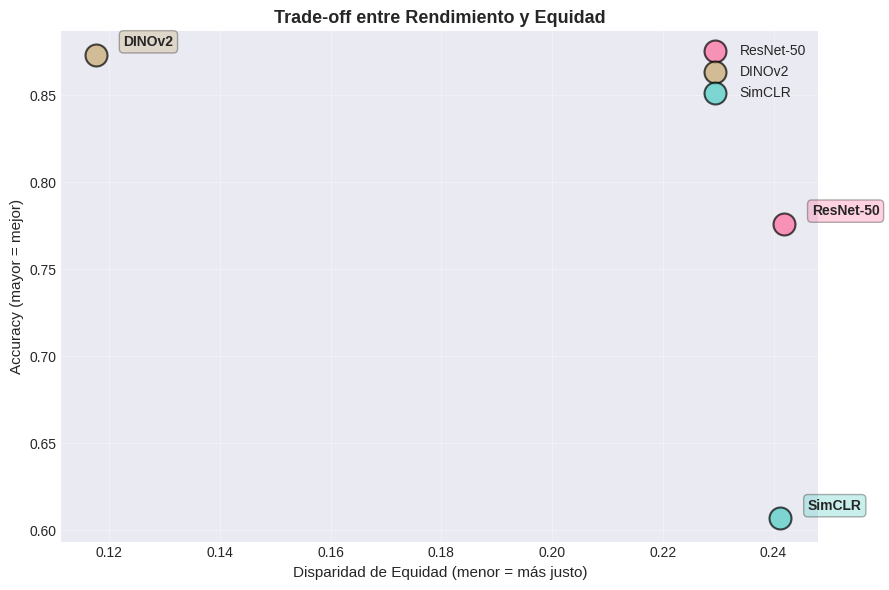

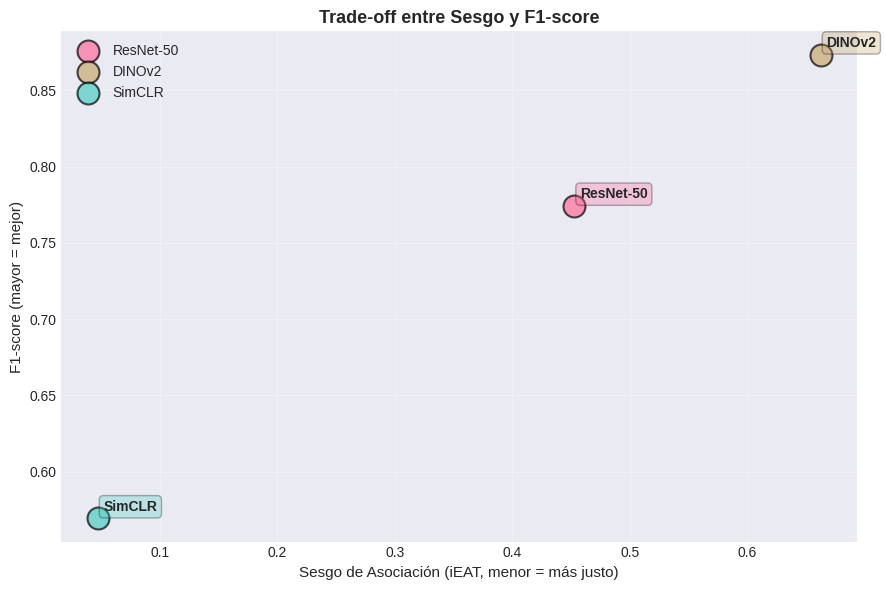

In [21]:
# Trade-off entre Equidad y Rendimiento

# Crear DataFrame con datos relevantes
tradeoff_df = pd.DataFrame({
    'Modelo': summary_df['Modelo'],
    'Tipo': summary_df['Tipo'],
    'Accuracy': summary_df['Accuracy'].astype(float),
    'F1-score': summary_df['F1-score'].astype(float),
    'Disparidad Equidad': summary_df['Disparidad Accuracy'].astype(float),
    'Sesgo (iEAT)': summary_df['Sesgo (iEAT)'].astype(float)
})

color_map = {
    'ResNet-50': '#FF6B9D',
    'DINOv2': '#C8A96F',
    'SimCLR': '#4ECDC4'
}

# Visualizar trade-off entre Equidad y Accuracy
plt.figure(figsize=(9, 6))
for _, row in tradeoff_df.iterrows():
    color = color_map[row['Modelo']]
    plt.scatter(row['Disparidad Equidad'], row['Accuracy'],
                s=250, color=color, alpha=0.7, edgecolors='black', linewidth=1.5,
                label=row['Modelo'])

    # Anotar nombres
    plt.text(row['Disparidad Equidad'] + 0.005, row['Accuracy'] + 0.005,
             row['Modelo'], fontsize=10, weight='bold',
             bbox=dict(boxstyle='round,pad=0.3', facecolor=color, alpha=0.3))

plt.xlabel('Disparidad de Equidad (menor = más justo)', fontsize=11)
plt.ylabel('Accuracy (mayor = mejor)', fontsize=11)
plt.title('Trade-off entre Rendimiento y Equidad', fontsize=13, fontweight='bold')
plt.grid(alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

# Visualizar Sesgo vs F1
plt.figure(figsize=(9, 6))
for _, row in tradeoff_df.iterrows():
    color = color_map[row['Modelo']]
    plt.scatter(row['Sesgo (iEAT)'], row['F1-score'],
                s=250, color=color, alpha=0.7, edgecolors='black', linewidth=1.5,
                label=row['Modelo'])

    plt.text(row['Sesgo (iEAT)'] + 0.005, row['F1-score'] + 0.005,
             row['Modelo'], fontsize=10, weight='bold',
             bbox=dict(boxstyle='round,pad=0.3', facecolor=color, alpha=0.3))

plt.xlabel('Sesgo de Asociación (iEAT, menor = más justo)', fontsize=11)
plt.ylabel('F1-score (mayor = mejor)', fontsize=11)
plt.title('Trade-off entre Sesgo y F1-score', fontsize=13, fontweight='bold')
plt.grid(alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

## 12. GRADCAM


ANÁLISIS GRADCAM (sobre el clasificador de género)
  ⚠ DINOv2 es un Vision Transformer: Grad-CAM convolucional no aplica. Solo ResNet-50 y SimCLR.

2. Generando visualizaciones GradCAM comparativas...


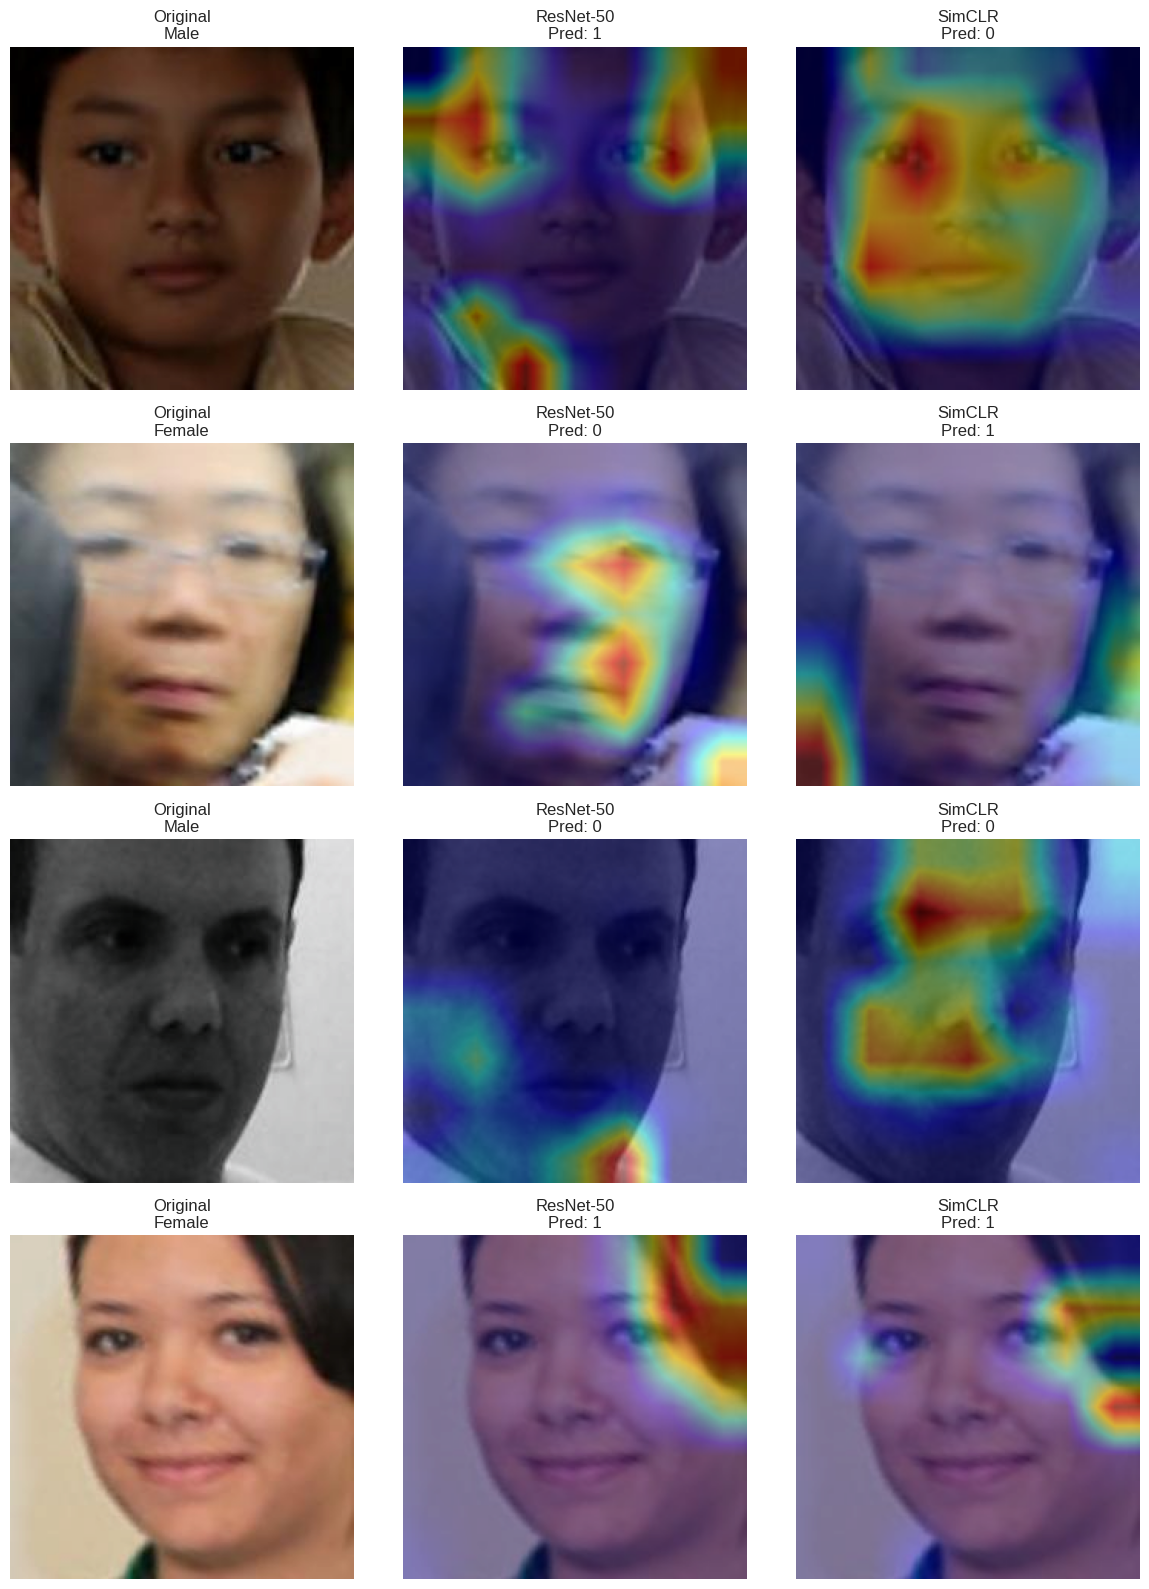


3. Analizando patrones de atención por grupo demográfico...


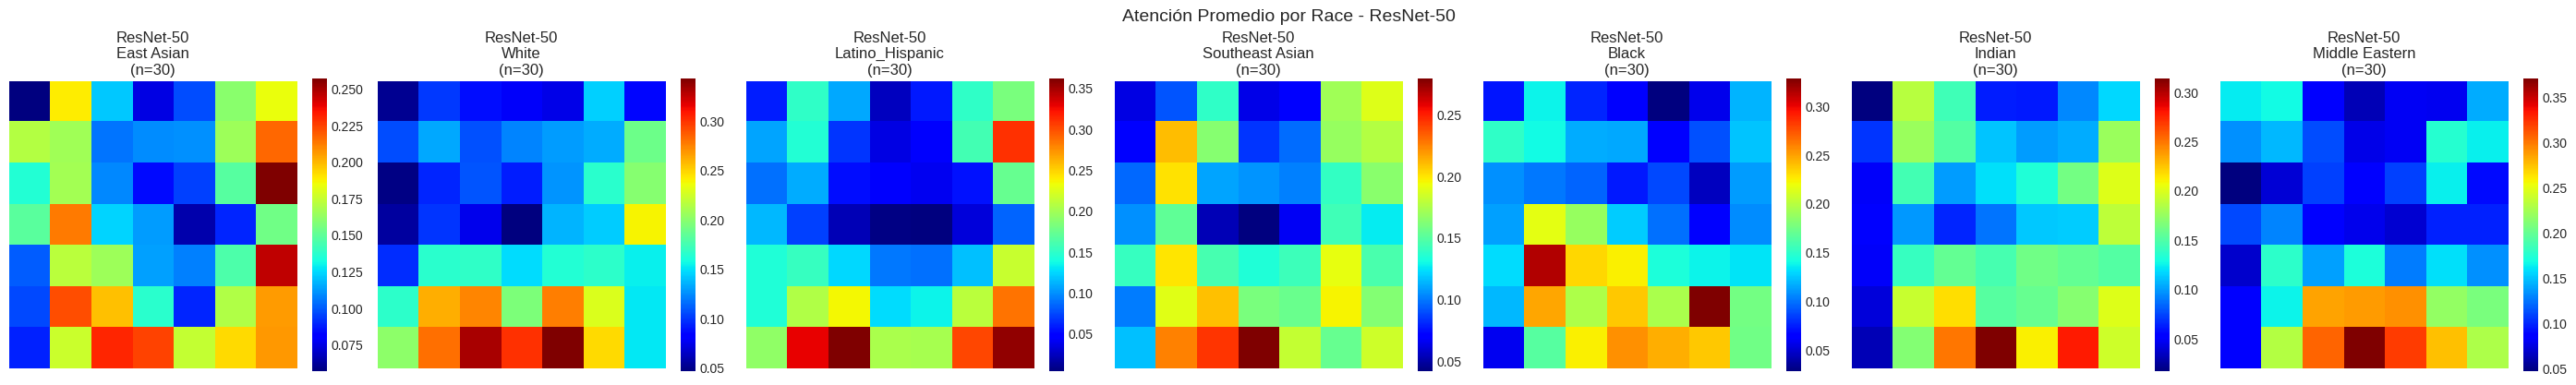

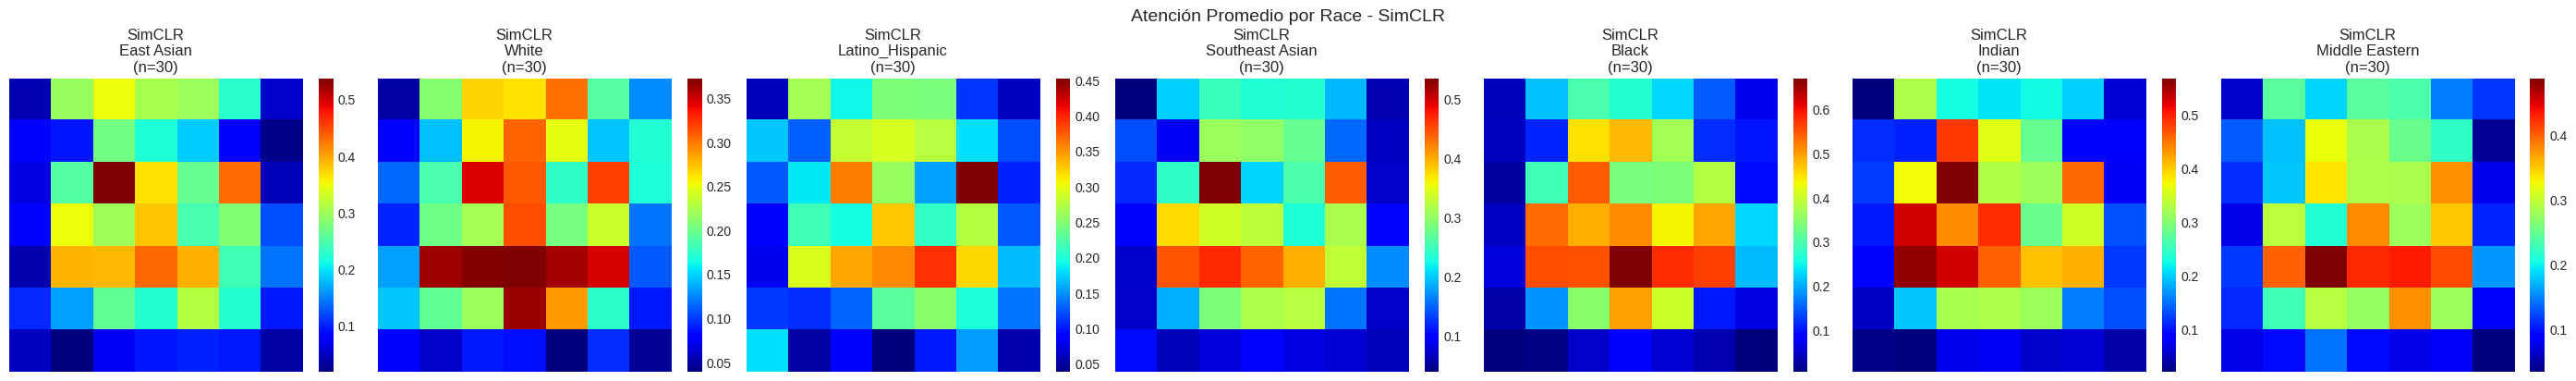

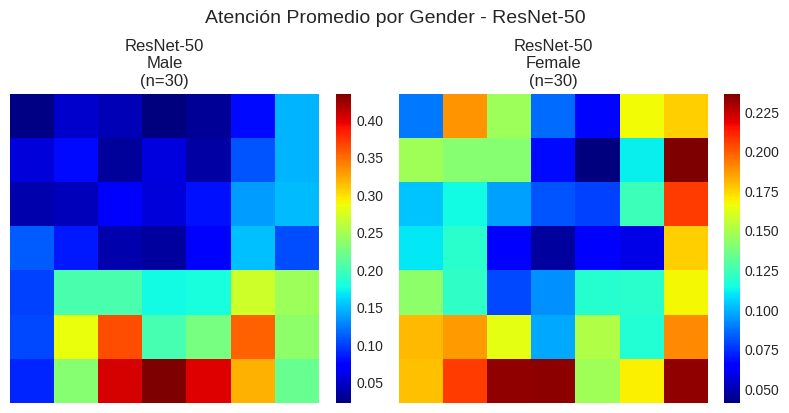


✓ Análisis GradCAM completado


In [22]:
# @title
class GradCAM:
    """
    Implementación de GradCAM para visualizar regiones importantes
    en las decisiones del modelo.
    """
    def __init__(self, model, target_layer):
        """
        Args:
            model: Modelo de PyTorch
            target_layer: Capa objetivo para GradCAM (típicamente última capa convolucional)
        """
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Registrar hook de forward; el gradiente se captura con un hook sobre el tensor
        self.handle = target_layer.register_forward_hook(self.save_activation)

    def remove(self):
        self.handle.remove()

    def save_activation(self, module, input, output):
        """Guarda las activaciones de la capa objetivo"""
        self.activations = output.detach()
        output.register_hook(lambda grad: setattr(self, 'gradients', grad.detach()))

    def generate_cam(self, input_image, target_class=None):
        """
        Genera el mapa de calor GradCAM

        Args:
            input_image: Tensor de imagen [1, C, H, W]
            target_class: Clase objetivo (si es None, usa la clase predicha)

        Returns:
            cam: Mapa de calor normalizado
            prediction: Clase predicha
        """
        self.model.eval()

        # Forward pass
        output = self.model(input_image)

        if target_class is None:
            target_class = output.argmax(dim=1).item()

        # Backward pass
        self.model.zero_grad()
        class_loss = output[0, target_class]
        class_loss.backward()

        # Calcular GradCAM
        gradients = self.gradients[0]
        activations = self.activations[0]

        # Pooling de gradientes
        weights = gradients.mean(dim=(1, 2), keepdim=True)

        # Combinación ponderada
        cam = (weights * activations).sum(dim=0)

        # ReLU para mantener solo influencias positivas
        cam = F.relu(cam)

        # Normalizar
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam.cpu().numpy(), target_class


def visualize_gradcam(model, image_tensor, original_image, target_layer,
                      model_name, target_class=None):
    """
    Visualiza GradCAM para una imagen

    Args:
        model: Modelo de PyTorch
        image_tensor: Tensor de imagen normalizado [1, C, H, W]
        original_image: Imagen PIL original
        target_layer: Capa objetivo del modelo
        model_name: Nombre del modelo (para el título)
        target_class: Clase objetivo (opcional)
    """
    # Crear instancia de GradCAM
    gradcam = GradCAM(model, target_layer)
    cam, predicted_class = gradcam.generate_cam(image_tensor, target_class)
    gradcam.remove()

    # Redimensionar CAM al tamaño de la imagen original
    original_size = original_image.size
    cam_resized = cv2.resize(cam, original_size)

    # Convertir imagen PIL a numpy
    img_np = np.array(original_image)

    # Crear heatmap
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    # Superponer heatmap en imagen original
    superimposed = heatmap * 0.4 + img_np * 0.6
    superimposed = np.clip(superimposed, 0, 255).astype(np.uint8)

    return cam_resized, heatmap, superimposed, predicted_class


def compare_gradcam_models(fairface_loader, models_dict, num_samples=6):
    """
    Compara visualizaciones GradCAM entre diferentes modelos

    Args:
        fairface_loader: DataLoader de FairFace
        models_dict: Diccionario con modelos y sus capas objetivo
                     {'nombre': (modelo, capa_objetivo)}
        num_samples: Número de imágenes a visualizar
    """
    # Obtener algunas imágenes
    dataiter = iter(fairface_loader)
    batch = next(dataiter)

    num_models = len(models_dict)
    fig, axes = plt.subplots(num_samples, num_models + 1,
                            figsize=(4 * (num_models + 1), 4 * num_samples))

    if num_samples == 1:
        axes = axes.reshape(1, -1)

    for idx in range(min(num_samples, len(batch['image']))):
        image_tensor = batch['image'][idx].unsqueeze(0).to(device)

        # Convertir tensor a imagen PIL
        img_np = batch['image'][idx].cpu().permute(1, 2, 0).numpy()
        img_np = img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img_np = np.clip(img_np, 0, 1)
        original_image = Image.fromarray((img_np * 255).astype(np.uint8))

        # Mostrar imagen original
        axes[idx, 0].imshow(original_image)
        axes[idx, 0].set_title(f'Original\n{batch["label_name"][idx]}')
        axes[idx, 0].axis('off')

        # Generar GradCAM para cada modelo
        for col_idx, (model_name, (model, target_layer)) in enumerate(models_dict.items(), start=1):
            try:
                _, _, superimposed, pred_class = visualize_gradcam(
                    model, image_tensor, original_image, target_layer, model_name
                )

                axes[idx, col_idx].imshow(superimposed)
                axes[idx, col_idx].set_title(f'{model_name}\nPred: {pred_class}')
                axes[idx, col_idx].axis('off')
            except Exception as e:
                axes[idx, col_idx].text(0.5, 0.5, f'Error: {str(e)[:20]}',
                                       ha='center', va='center')
                axes[idx, col_idx].axis('off')

    plt.tight_layout()
    plt.savefig('gradcam_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()


def analyze_gradcam_bias(fairface_loader, model, target_layer,
                        model_name, demographics_key='race', num_samples=50):
    """
    Analiza si GradCAM muestra patrones diferentes según demografía

    Args:
        fairface_loader: DataLoader
        model: Modelo a analizar
        target_layer: Capa objetivo
        model_name: Nombre del modelo
        demographics_key: 'race', 'gender' o 'age'
        num_samples: Número de muestras a analizar por grupo
    """
    gradcam = GradCAM(model, target_layer)

    # Almacenar mapas de calor por grupo demográfico
    demographic_cams = {}

    samples_per_group = {}

    for batch in fairface_loader:
        images = batch['image'].to(device)
        demographics = batch['demographics'][demographics_key]

        for i in range(len(images)):
            demo_group = demographics[i]

            if demo_group not in samples_per_group:
                samples_per_group[demo_group] = 0
                demographic_cams[demo_group] = []

            if samples_per_group[demo_group] >= num_samples:
                continue

            image_tensor = images[i].unsqueeze(0)
            cam, _ = gradcam.generate_cam(image_tensor)

            demographic_cams[demo_group].append(cam)
            samples_per_group[demo_group] += 1

        # Verificar si hemos recolectado suficientes muestras
        if all(count >= num_samples for count in samples_per_group.values()):
            break

    # Calcular mapas promedio por grupo
    avg_cams = {}
    for group, cams in demographic_cams.items():
        if len(cams) > 0:
            avg_cams[group] = np.mean(cams, axis=0)

    # Visualizar
    num_groups = len(avg_cams)
    fig, axes = plt.subplots(1, num_groups, figsize=(4 * num_groups, 4))

    if num_groups == 1:
        axes = [axes]

    for idx, (group, cam) in enumerate(avg_cams.items()):
        im = axes[idx].imshow(cam, cmap='jet')
        axes[idx].set_title(f'{model_name}\n{group}\n(n={len(demographic_cams[group])})')
        axes[idx].axis('off')
        plt.colorbar(im, ax=axes[idx], fraction=0.046)

    plt.suptitle(f'Atención Promedio por {demographics_key.capitalize()} - {model_name}',
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(f'gradcam_bias_{model_name}_{demographics_key}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

    return avg_cams

class EmbeddingClassifier(nn.Module):
    """Backbone + regresión logística entrenada, como un único modelo diferenciable.
    Así Grad-CAM explica la decisión de GÉNERO (no los logits de ImageNet)."""
    def __init__(self, backbone, clf):
        super().__init__()
        self.backbone = backbone
        self.register_buffer('w', torch.tensor(clf.coef_[0], dtype=torch.float32))
        self.register_buffer('b', torch.tensor(clf.intercept_[0], dtype=torch.float32))

    def forward(self, x):
        f = self.backbone(x).flatten(1)
        f = f / (f.norm(dim=1, keepdim=True) + 1e-8)   # misma normalización L2 que en el entrenamiento
        z = f @ self.w + self.b
        return torch.stack([-z / 2, z / 2], dim=1)     # logit(clase 1) - logit(clase 0) = z


print('\n' + '='*80)
print('ANÁLISIS GRADCAM (sobre el clasificador de género)')
print('='*80)

def build_gradcam_model(resnet_like, clf):
    backbone = nn.Sequential(*list(resnet_like.children())[:-1]).to(device).eval()  # hasta avgpool
    model = EmbeddingClassifier(backbone, clf).to(device).eval()
    return model, backbone[7][-1]   # backbone[7] = layer4; último Bottleneck

resnet_cam_model, resnet_target_layer = build_gradcam_model(resnet50, clf_resnet)
simclr_cam_model, simclr_target_layer = build_gradcam_model(simclr_model, clf_simclr)

if dinov2_model is not None:
    print('  ⚠ DINOv2 es un Vision Transformer: Grad-CAM convolucional no aplica. Solo ResNet-50 y SimCLR.')

models_for_gradcam = {
    'ResNet-50': (resnet_cam_model, resnet_target_layer),
    'SimCLR': (simclr_cam_model, simclr_target_layer)
}

print('\n2. Generando visualizaciones GradCAM comparativas...')
compare_gradcam_models(fairface_loader, models_for_gradcam, num_samples=4)

print('\n3. Analizando patrones de atención por grupo demográfico...')
resnet_race_cams = analyze_gradcam_bias(fairface_loader, resnet_cam_model, resnet_target_layer,
                                        'ResNet-50', demographics_key='race', num_samples=30)
simclr_race_cams = analyze_gradcam_bias(fairface_loader, simclr_cam_model, simclr_target_layer,
                                        'SimCLR', demographics_key='race', num_samples=30)
resnet_gender_cams = analyze_gradcam_bias(fairface_loader, resnet_cam_model, resnet_target_layer,
                                          'ResNet-50', demographics_key='gender', num_samples=30)

print('\n✓ Análisis GradCAM completado')
print('='*80)


**Interpretación de Grad-CAM** (sobre la decisión de género del clasificador lineal, clase predicha; 4 imágenes de ejemplo y 30 por grupo para los promedios):

- **ResNet-50** reparte la atención de forma más dispersa: junto a zonas de la cara aparecen regiones periféricas (pelo, cuello, ropa, fondo). En el mapa promedio por género, los hombres concentran la atención en la parte inferior de la imagen, mientras que en las mujeres se reparte por más zonas, incluido el pelo.
- **SimCLR** concentra la atención en la región central de la imagen (cara) en todos los grupos raciales.
- Los mapas promedio son de **7×7**, cada panel tiene su **propia escala de color** y solo hay 30 imágenes por grupo, así que no permiten comparar intensidades entre grupos ni afirmar que un grupo reciba "más atención". Son ilustrativos y **no demuestran causalidad**: no indican que el modelo use la raza como señal.
- Además, el clasificador de SimCLR rinde peor (ver sección 13), por lo que sus mapas explican un modelo poco fiable.


## 13. Análisis Crítico y Conclusiones

### Resultados

| Modelo | Tipo | Accuracy | F1 | Disp. accuracy | Disp. TPR | Disp. DP | iEAT simplificado |
|---|---|---|---|---|---|---|---|
| ResNet-50 | Supervisado | 0.776 | 0.774 | 0.242 | 0.205 | 0.208 | 0.453 |
| DINOv2-small | Auto-supervisado | **0.873** | **0.874** | **0.118** | 0.161 | 0.231 | 0.662 |
| SimCLR (ResNet-50) | Auto-supervisado | 0.607 | 0.569 | 0.241 | **0.125** | **0.178** | 0.047 |

*(Disparidad = máximo − mínimo entre los 7 grupos raciales.)*

### Rendimiento general
**DINOv2 es claramente el mejor** (≈87 % de accuracy), seguido de ResNet-50 (≈78 %). **SimCLR rinde mal en esta configuración** (≈61 %, con F1 por debajo del accuracy). Sus gráficas de equidad muestran por qué: predice "Male" (clase positiva) en el 70–88 % de las imágenes de todos los grupos y tiene una FPR de 0.5–0.85, es decir, se comporta como un clasificador sesgado hacia la clase más frecuente (Male). Una explicación plausible, **no comprobada**, es que el clasificador (regresión logística con regularización por defecto sobre embeddings normalizados L2) infraajusta las características de SimCLR; habría que probar estandarizar las características o ajustar la regularización por validación cruzada. Hasta entonces, **este resultado no permite concluir nada sobre SimCLR ni sobre el aprendizaje contrastivo en general**.

### Disparidad entre grupos raciales
Con ≈107 imágenes por grupo, el error estándar de la accuracy de cada grupo es de ≈0.03–0.04, de modo que, solo por azar, la diferencia máx–mín entre 7 grupos ronda **0.09–0.11** (estimación aproximada).

- **ResNet-50:** su disparidad en accuracy (0.24) duplica con creces ese margen, así que es evidencia razonable de rendimiento desigual. Según las gráficas, rinde peor en los grupos Black y Latino_Hispanic y mejor en Middle Eastern.
- **DINOv2:** su disparidad (0.12) está en el rango que cabría esperar por azar; no hay evidencia clara de desigualdad en accuracy, aunque su grupo con peor resultado vuelve a ser Black. Es el modelo con mejor accuracy en casi todos los grupos.
- **SimCLR:** su disparidad (0.24) refleja un clasificador degenerado y no debe interpretarse como sesgo del modelo.
- **Demographic Parity:** las tasas de predicción positiva difieren entre grupos en los tres modelos (0.18–0.23), pero esta métrica es difícil de leer aquí: si la proporción real de hombres difiere entre grupos de la muestra, una diferencia en DP no implica sesgo. TPR/FPR y accuracy por grupo son más informativas.

### Sesgo asociativo (iEAT simplificado)
Los valores **no son comparables entre modelos** y no sostienen conclusiones sobre quién es "más sesgado". El 0.047 de SimCLR no significa "casi sin sesgo": es compatible con embeddings cuyos centroides quedan casi alineados por un componente común grande (algo plausible con activaciones no negativas de una ResNet), y DINOv2 (CLS token de 384 dimensiones) tiene otra geometría. En la versión anterior, con los mismos embeddings de ResNet-50, la métrica dio exactamente el mismo valor (0.453), como era de esperar. Para medir sesgo asociativo de verdad hace falta el iEAT original (conjuntos de atributos y tamaño de efecto) o un análisis como la probabilidad de predecir la raza desde el embedding.

### Qué se puede y qué no se puede concluir
- **Se puede decir:** en esta muestra, DINOv2-small supera a ResNet-50 en accuracy y su disparidad entre grupos no supera lo esperable por azar, mientras que ResNet-50 muestra una disparidad de accuracy mayor que el azar, con peor rendimiento en los grupos Black y Latino_Hispanic.
- **No se puede decir:** que los modelos auto-supervisados sean más o menos sesgados que los supervisados. La comparación mezcla arquitectura (ViT-S vs ResNet-50), datos de preentrenamiento y paradigma; SimCLR no está bien entrenado como clasificador aquí; y el iEAT simplificado no es comparable entre modelos.
- Un buen rendimiento medio no garantiza equidad: los resultados por grupo deben revisarse siempre aunque el modelo sea muy preciso.

### Limitaciones del estudio
1. **Tamaño y estadística:** 2 500 imágenes (750 de test), una sola partición y una sola semilla; sin intervalos de confianza.
2. **Clasificador:** regresión logística con hiperparámetros por defecto, no ajustados por modelo; probablemente perjudica a SimCLR.
3. **Modelos:** solo tres, con arquitectura y datos de preentrenamiento distintos.
4. **iEAT simplificado:** no es el iEAT original y no es comparable entre modelos (sección 10).
5. **Demographic Parity:** no controla las diferencias reales de género entre grupos.
6. **Grad-CAM:** resolución 7×7, 30 imágenes por grupo, escalas de color independientes; solo para arquitecturas convolucionales (DINOv2 queda fuera).
7. **Etiquetas:** FairFace usa categorías raciales y de género binarias anotadas por terceros; son simplificaciones de realidades más complejas.

### Implicaciones éticas
Elegir un modelo solo por su accuracy media puede ocultar diferencias entre grupos, y decidir cuánta precisión se cede por más equidad es una decisión que debe tomarse y documentarse de forma explícita. Estos resultados son exploratorios y **no justifican por sí solos recomendar ni descartar un modelo** para un uso real, y menos aún en decisiones que afecten a personas.

### Próximos pasos
1. Estandarizar las características y ajustar la regularización por validación cruzada para cada modelo, y volver a ejecutar.
2. Añadir intervalos de confianza (bootstrap) y repetir con varias semillas/particiones.
3. Usar el iEAT original o una métrica de separabilidad comparable entre modelos.
4. Incluir más modelos y tamaños (p. ej., DINOv2-base, otro ResNet supervisado y otro auto-supervisado de la misma arquitectura) para separar el efecto del paradigma del de la arquitectura.
5. Evaluar con el conjunto de entrenamiento completo de FairFace en lugar de un subconjunto.


## 14. Referencias

[1] Sirotkin, K., Carballeira, P., & Escudero-Viñolo, M. (2022). A study on the distribution of social biases in self-supervised learning visual models. *IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*, 10442-10451.

[2] Wang, Z., Qinami, K., Karakozis, I. C., Gehrig, M., Bashirov, Y., & Geiger, A. (2020). Towards fairness in visual recognition: Effective strategies for bias mitigation. *IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*, 8919-8928.

[3] Caliskan, A., Bryson, J. J., & Narayanan, A. (2017). Semantics derived automatically from language corpora contain human-like biases. *Science*, 356(6334), 183-186.

[4] Steed, R., & Caliskan, A. (2021). Image representations learned with unsupervised pre-training contain human-like biases. *ACM FAccT*.

[5] Kärkkäinen, K., & Joo, J. (2021). FairFace: Face attribute dataset for balanced race, gender, and age for bias measurement and mitigation. *WACV*.
